# 🕸️ Patient-Similarity Graphs for Pharyngitis Type Classification

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/negarsh76/Patient-Similarity-Graph/blob/main/notebooks/patient_similarity_graph.ipynb)

Patients are represented by 20 binary symptoms and connected when their symptom profiles are similar. The resulting **graph** is used to:

1. compare it with feature-based classifiers (decision tree, random forest, logistic regression),
2. discover **communities** of patients with Louvain,
3. learn **node2vec-style embeddings**, using biased random walks factorised with PPMI + SVD, the closed form of skip-gram,
4. test whether the graph helps when **only a few diagnoses are known** (label propagation and graph-augmented features).

> ⚠️ **Data:** this notebook uses a **synthetic** dataset generated by [`data/make_synthetic.py`](../data/make_synthetic.py). The symptom prevalences are illustrative only, contain no real patient records, and must not be used for clinical decisions.

In [1]:
# On Colab, uncomment:
# !pip -q install networkx scikit-learn seaborn

In [2]:
import numpy as np, pandas as pd, networkx as nx, matplotlib.pyplot as plt, seaborn as sns
from pathlib import Path
plt.rcParams.update({"figure.dpi": 110}); sns.set_theme(style="whitegrid", font_scale=0.9)
ASSETS = Path("../assets"); ASSETS.mkdir(exist_ok=True)
PALETTE = {0: "#4C78A8", 1: "#E45756", 2: "#54A24B"}
NAMES = {0: "Type 0 (viral-like)", 1: "Type 1 (bacterial-like)", 2: "Type 2 (mixed)"}

URL = "https://raw.githubusercontent.com/negarsh76/Patient-Similarity-Graph/main/data/synthetic_patients.csv"
local = Path("../data/synthetic_patients.csv")
df = pd.read_csv(local if local.exists() else URL)
SYMPTOMS = list(df.columns[1:-1]); X = df[SYMPTOMS].to_numpy(); y = df["pharyngitis_type"].to_numpy(); N = len(df)
print(df.shape); df.head()

(400, 22)


,patient,feeling cold,sore throat,cephalalgia,myalgia,rhinorrhea,diarrhea,vomit,cough,pyrexia,...,sputum,abdominal pain,vertigo,sternutation,eye infection,otalgia,nasal congestion,asthma,anorexia,pharyngitis_type
0,P000,1,1,0,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,1,1
1,P001,0,0,1,0,0,0,0,0,1,...,0,1,0,0,0,0,0,0,1,1
2,P002,1,1,1,1,1,0,0,0,1,...,0,0,0,1,0,0,1,0,0,0
3,P003,1,1,1,0,0,0,0,0,1,...,0,0,0,0,0,1,0,0,0,1
4,P004,0,0,0,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,0,0


## 1 · Exploring the symptoms

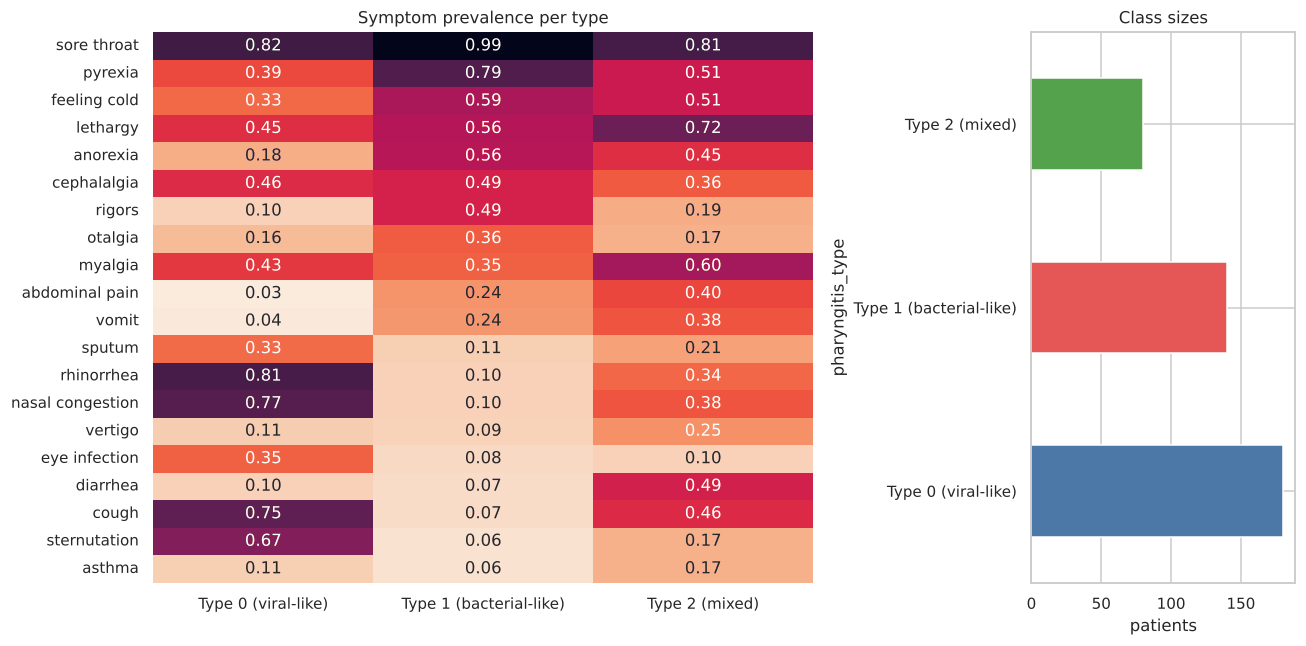

In [3]:
prev = df.groupby("pharyngitis_type")[SYMPTOMS].mean().T
prev.columns = [NAMES[c] for c in prev.columns]
fig, (a, b) = plt.subplots(1, 2, figsize=(12, 6), gridspec_kw={"width_ratios": [3, 1.2]})
sns.heatmap(prev.sort_values(prev.columns[1], ascending=False), annot=True, fmt=".2f", cmap="rocket_r", cbar=False, ax=a)
a.set_title("Symptom prevalence per type")
df["pharyngitis_type"].map(NAMES).value_counts().plot.barh(ax=b, color=[PALETTE[0], PALETTE[1], PALETTE[2]])
b.set_title("Class sizes"); b.set_xlabel("patients")
fig.tight_layout(); fig.savefig(ASSETS / "prevalence.png", dpi=120, bbox_inches="tight"); plt.show()

## 2 · Feature-based baselines (5-fold CV)

In [4]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

cv = StratifiedKFold(5, shuffle=True, random_state=0)
models = {"Decision tree (depth 4)": DecisionTreeClassifier(max_depth=4, random_state=0),
          "Random forest": RandomForestClassifier(300, random_state=0),
          "Logistic regression": LogisticRegression(max_iter=1000)}
rows = []
for name, m in models.items():
    r = cross_validate(m, X, y, cv=cv, scoring=["accuracy", "f1_macro"])
    rows.append({"model": name, "accuracy": r["test_accuracy"].mean(), "macro-F1": r["test_f1_macro"].mean()})
baselines = pd.DataFrame(rows).set_index("model").round(3); baselines

,accuracy,macro-F1
model,,
Decision tree (depth 4),0.732,0.644
Random forest,0.822,0.753
Logistic regression,0.860,0.825


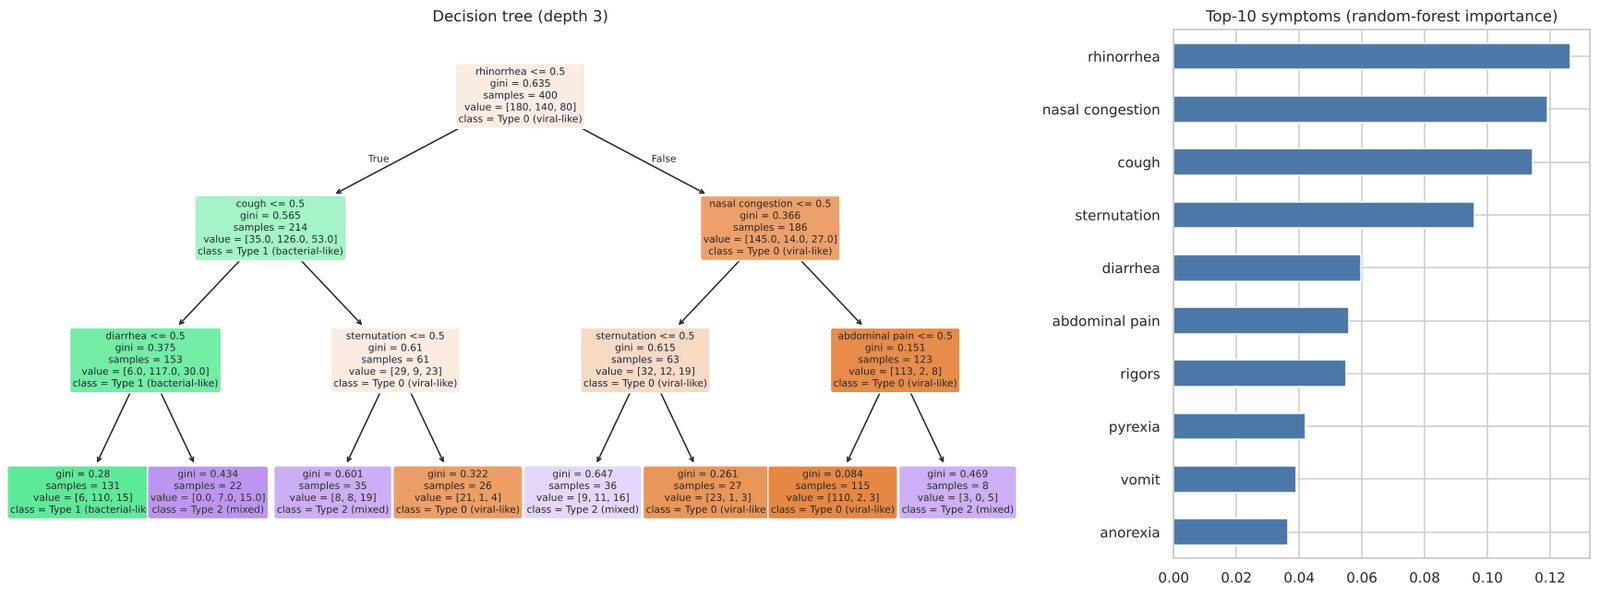

In [5]:
tree = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X, y)
fig, (a, b) = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [2.4, 1]})
plot_tree(tree, feature_names=SYMPTOMS, class_names=[NAMES[i] for i in range(3)], filled=True, rounded=True, fontsize=7, ax=a)
a.set_title("Decision tree (depth 3)")
rf = models["Random forest"].fit(X, y)
imp = pd.Series(rf.feature_importances_, SYMPTOMS).sort_values().tail(10)
imp.plot.barh(ax=b, color="#4C78A8"); b.set_title("Top-10 symptoms (random-forest importance)")
fig.tight_layout(); fig.savefig(ASSETS / "tree_importance.png", dpi=120, bbox_inches="tight"); plt.show()

## 3 · Building the patient-similarity graph
The original version linked two patients whenever they shared a positive symptom, which made the graph almost complete. Here each patient is instead connected to its **k = 10 most similar** patients by **Jaccard similarity** of their symptom sets, $J(a,b)=\frac{|a\cap b|}{|a\cup b|}$. The similarity is kept as the edge weight.

In [6]:
def jaccard_knn_graph(X, k=10):
    inter = X @ X.T; size = X.sum(1)
    J = inter / np.maximum(size[:, None] + size[None, :] - inter, 1); np.fill_diagonal(J, 0)
    G = nx.Graph(); G.add_nodes_from(range(len(X)))
    for i in range(len(X)):
        for j in np.argsort(-J[i])[:k]:
            G.add_edge(i, int(j), weight=float(J[i, j]))
    return G

G = jaccard_knn_graph(X)
homophily = np.mean([y[u] == y[v] for u, v in G.edges()])
print(f"{G.number_of_nodes()} nodes · {G.number_of_edges()} edges · connected: {nx.is_connected(G)}")
print(f"edge homophily (same type on both ends): {homophily:.2%}  (random graph would give {sum((np.bincount(y)/N)**2):.2%})")

400 nodes · 2871 edges · connected: True
edge homophily (same type on both ends): 73.67%  (random graph would give 36.50%)


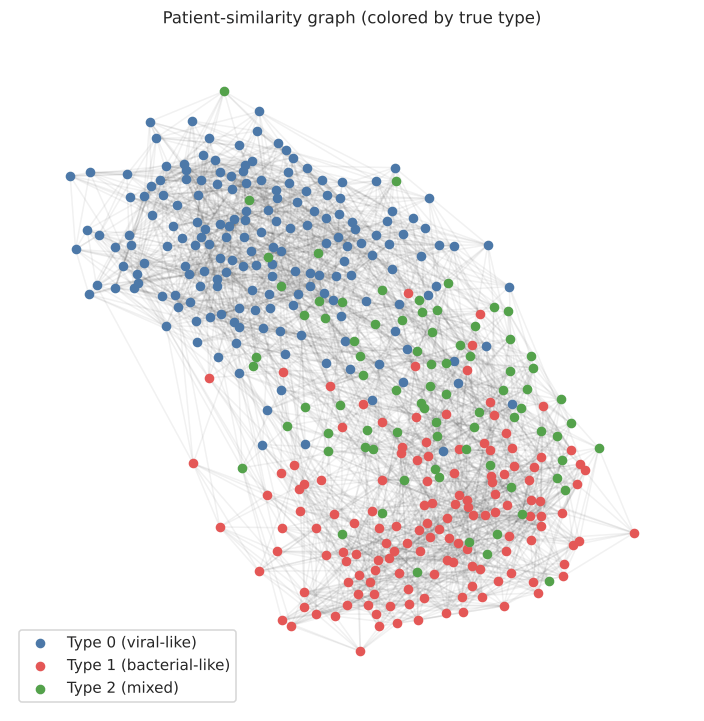

In [7]:
pos = nx.spring_layout(G, weight="weight", seed=3, k=0.12, iterations=200)
fig, ax = plt.subplots(figsize=(8, 8))
nx.draw_networkx_edges(G, pos, alpha=0.06, ax=ax)
for c in range(3):
    nodes = [n for n in G if y[n] == c]
    nx.draw_networkx_nodes(G, pos, nodelist=nodes, node_size=28, node_color=PALETTE[c], label=NAMES[c], ax=ax)
ax.legend(loc="lower left", frameon=True); ax.set_title("Patient-similarity graph (colored by true type)"); ax.axis("off")
fig.savefig(ASSETS / "graph.png", dpi=120, bbox_inches="tight"); plt.show()

## 4 · Unsupervised: communities & node2vec-style embeddings
**Embeddings.** Weighted random walks are run on the graph. The (node, context) co-occurrence counts inside a window are turned into a **positive PMI matrix** and factorised with SVD. Levy & Goldberg (2014) showed that this is the matrix skip-gram implicitly factorises, so the result is the same kind of embedding node2vec or DeepWalk produces, without needing `gensim`.

In [8]:
def walk_embeddings(G, dim=32, walks_per_node=20, walk_len=40, window=5, seed=0):
    rng = np.random.default_rng(seed); n = G.number_of_nodes()
    nbrs = [np.array(list(G.neighbors(i))) for i in range(n)]
    probs = [np.array([G[i][j]["weight"] for j in nbrs[i]]) for i in range(n)]
    probs = [p / p.sum() for p in probs]
    C = np.zeros((n, n))
    for _ in range(walks_per_node):
        for s in range(n):
            walk = [s]
            for _ in range(walk_len - 1):
                c = walk[-1]; walk.append(nbrs[c][rng.choice(len(nbrs[c]), p=probs[c])])
            for a, u in enumerate(walk):
                for v in walk[max(0, a - window):a] + walk[a + 1:a + 1 + window]:
                    C[u, v] += 1
    ppmi = np.maximum(np.log(np.maximum(C * C.sum() / (C.sum(1, keepdims=True) * C.sum(0, keepdims=True)), 1e-12)), 0)
    U, s, _ = np.linalg.svd(ppmi)
    return U[:, :dim] * np.sqrt(s[:dim])

E = walk_embeddings(G)
E.shape

(400, 32)

In [9]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, f1_score, confusion_matrix
from scipy.optimize import linear_sum_assignment

def match(y_true, labels):
    """Map cluster ids to classes with the Hungarian algorithm."""
    cm = confusion_matrix(y_true, labels, labels=range(max(y_true.max(), labels.max()) + 1))
    r, c = linear_sum_assignment(-cm); mapping = dict(zip(c, r))
    return np.array([mapping.get(l, -1) for l in labels])

comms = nx.community.louvain_communities(G, weight="weight", resolution=0.6, seed=0)
louvain = np.zeros(N, int)
for cid, members in enumerate(comms): louvain[list(members)] = cid

clusterings = {"k-means on raw symptoms": KMeans(3, n_init=20, random_state=0).fit_predict(X),
               "k-means on graph embeddings": KMeans(3, n_init=20, random_state=0).fit_predict(E),
               f"Louvain communities ({len(comms)})": louvain}
pd.DataFrame({k: {"ARI": adjusted_rand_score(y, l), "NMI": normalized_mutual_info_score(y, l),
                  "matched macro-F1": f1_score(y, match(y, l), average="macro")}
              for k, l in clusterings.items()}).T.round(3)

,ARI,NMI,matched macro-F1
k-means on raw symptoms,0.488,0.425,0.625
k-means on graph embeddings,0.494,0.429,0.696
Louvain communities (2),0.517,0.451,0.559


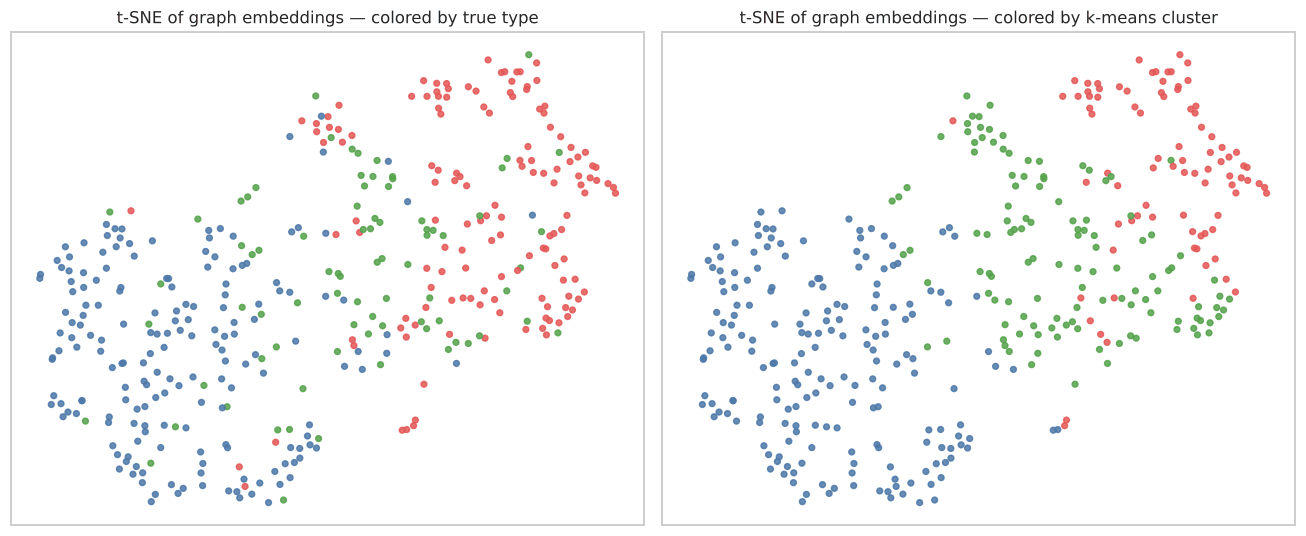

In [10]:
from sklearn.manifold import TSNE
Z = TSNE(2, perplexity=30, random_state=0, init="pca").fit_transform(E)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, lab, title in [(axes[0], y, "true type"), (axes[1], clusterings["k-means on graph embeddings"], "k-means cluster")]:
    ax.scatter(*Z.T, c=[list(PALETTE.values())[l % 3] for l in lab], s=14, alpha=.85)
    ax.set_title(f"t-SNE of graph embeddings — colored by {title}"); ax.set_xticks([]); ax.set_yticks([])
fig.tight_layout(); fig.savefig(ASSETS / "embeddings_tsne.png", dpi=120, bbox_inches="tight"); plt.show()

## 5 · Few labels: does the graph help?
Suppose only **3–40 %** of patients have a confirmed diagnosis. Four approaches are compared, each averaged over 20 random draws of the labelled set:

* **Decision tree** and **logistic regression** use the labelled patients' symptoms only.
* **Label propagation** uses only the graph: $F \leftarrow \alpha S F + (1-\alpha) Y$ with $S = D^{-1/2} W D^{-1/2}$, plus class-mass normalisation.
* **Graph-augmented logistic regression** feeds each patient's symptoms **plus their neighbourhood-averaged symptoms** ($\hat A X$, one step of an SGC/GCN layer) into the model.

In [11]:
W = nx.to_numpy_array(G, weight="weight")
Dm = np.diag(1 / np.sqrt(W.sum(1))); S = Dm @ W @ Dm
A = W + np.eye(N); Da = np.diag(1 / np.sqrt(A.sum(1))); A_hat = Da @ A @ Da
X_graph = np.hstack([X, A_hat @ X])                       # own symptoms + neighbourhood average

def label_propagation(idx, alpha=0.9, iters=100):
    Y0 = np.zeros((N, 3)); Y0[idx, y[idx]] = 1; F = Y0.copy()
    for _ in range(iters): F = alpha * S @ F + (1 - alpha) * Y0
    F = F / np.maximum(F.sum(0, keepdims=True), 1e-12) * np.maximum(Y0.sum(0), 1)   # class-mass normalisation
    return F.argmax(1)

fracs, res = [0.03, 0.05, 0.1, 0.2, 0.4], []
for f in fracs:
    for seed in range(20):
        rng = np.random.default_rng(seed); idx = rng.choice(N, max(3, int(f * N)), replace=False)
        if len(set(y[idx])) < 3: continue                   # need every class at least once
        test = np.setdiff1d(np.arange(N), idx)
        preds = {
            "Decision tree": DecisionTreeClassifier(max_depth=4, random_state=0).fit(X[idx], y[idx]).predict(X),
            "Logistic regression": LogisticRegression(max_iter=2000).fit(X[idx], y[idx]).predict(X),
            "Label propagation (graph only)": label_propagation(idx),
            "Graph-augmented log. regression": LogisticRegression(max_iter=2000).fit(X_graph[idx], y[idx]).predict(X_graph),
        }
        for name, p in preds.items():
            res.append({"labelled": f, "method": name, "macro-F1": f1_score(y[test], p[test], average="macro")})
res = pd.DataFrame(res)
summary = res.pivot_table(index="labelled", columns="method", values="macro-F1").round(3); summary

method,Decision tree,Graph-augmented log. regression,Label propagation (graph only),Logistic regression
labelled,,,,
0.03,0.545,0.600,0.551,0.569
0.05,0.575,0.665,0.596,0.640
0.10,0.633,0.731,0.640,0.732
0.20,0.646,0.765,0.620,0.767
0.40,0.664,0.785,0.595,0.789


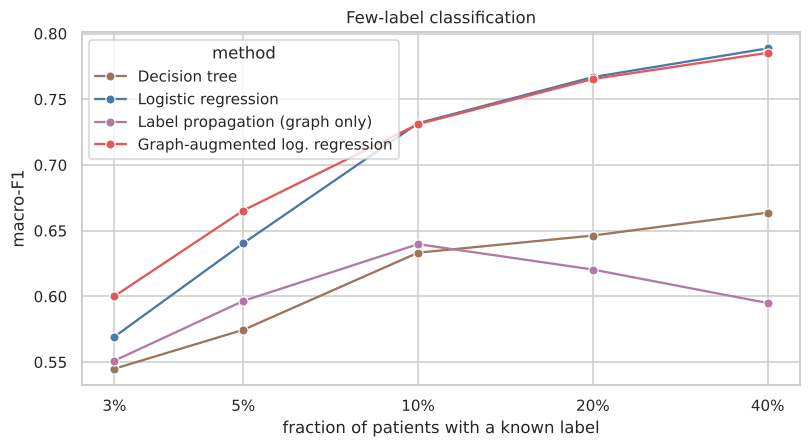

In [12]:
fig, ax = plt.subplots(figsize=(7.5, 4.2))
sns.lineplot(res, x="labelled", y="macro-F1", hue="method", marker="o", errorbar=None, ax=ax,
             palette=["#9D755D", "#4C78A8", "#B279A2", "#E45756"])
ax.set_xscale("log"); ax.set_xticks(fracs); ax.set_xticklabels([f"{int(f*100)}%" for f in fracs]); ax.minorticks_off()
ax.set_xlabel("fraction of patients with a known label"); ax.set_title("Few-label classification")
fig.tight_layout(); fig.savefig(ASSETS / "few_labels.png", dpi=120, bbox_inches="tight"); plt.show()

## Takeaways
* On this synthetic data, **logistic regression** is the strongest fully-supervised model. The symptoms combine roughly additively, so a linear model fits well.
* The **k-NN Jaccard graph** is strongly *homophilous*: about 74 % of edges connect patients of the same type, against 37 % by chance. That is why graph methods work at all.
* **Unsupervised** structure (communities or embeddings) recovers the types only partially, because the viral-like and mixed types overlap.
* **The graph on its own is not enough:** label propagation trails logistic regression once more than a handful of labels are available.
* **The graph as extra context helps where it matters:** adding neighbourhood-averaged symptoms gives the largest gain at **3–5 % labelled**, the realistic setting when confirmed diagnoses are expensive. With more labels, it converges to plain logistic regression.
* **Next steps:** a full GCN/GAT, learned graph construction, and validation on real (de-identified) clinical data.